## Evaluation and validation of borehole networks

In [1]:
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np

import pygfunction3 as gt3
import pygfunction as gt

#### Borefield parameters
3 boreholes connected in series.

In [2]:
# Borehole dimensions and field layout
L = 150.        # Borehole length [m]
D = 4.          # Borehole buried depth [m]
r_b = 0.075     # Borehole radius [m]
N_1 = 3         # Number of boreholes in x-direction
N_2 = 1         # Number of boreholes in y-direction
B = 7.5         # Borehole spacing [m]
# Borehole connectivity (boreholes are connected in series)
borehole_connectivity = [-1, 0, 1]

# Positions of the boreholes
p_head = np.array(
    [np.tile(B * np.arange(N_1), N_2), np.repeat(B * np.arange(N_2), N_1)]
).T
# Fluid mass flow rate (in kg/s)
m_flow = 0.1 * np.shape(p_head)[0]

# Pipe dimensions
n_p = 2             # Number of pipes
# Pipe inner radius (m)
r_p_in = 0.018
# Pipe outer radius (m)
r_p_out = 0.02

# Pipe positions
# Single U-tube [(x_1, y_1), (x_2, y_2)]
p = [(0.03, 0.00), (-0.03, 0.02)]

# Pipe properties
k_p = 0.4           # Pipe thermal conductivity (W/m.K)
epsilon = 2.12e-5   # Pipe roughness (in meters)

# Ground properties
k_s = 2.5           # Ground thermal conductivity (W/m.K)

# Grout properties
k_b = 1.5           # Grout thermal conductivity (W/m.K)

#### Fluid Properties
The fluid is propylene-glycol (20%).

In [3]:
# Fluid object
T_nominal = 20.
fluid = gt3.Fluid.from_scp(
    'PropyleneGlycol', T_nominal, x=0.2
)
cp_f = fluid.specific_heat()  # Fluid specific heat capacity (in J/kg.K)

#### Simulation conditions

In [4]:
# Inlet fluid temperature (in degrees Celsius)
T_f_in = -1.
# Borehole wall temperature (in degrees Celsius)
f_T_b = lambda _xi, _N, _i: 1. + np.add.outer(_i / 5, _xi**(_N - 1) - _xi / 3)

### Solution using pygfunction3

In [5]:
# Borefield object
field = gt3.Borefield(L=L, D=D, r_b=r_b, p_head=p_head)
# Pipe object
pipe = gt3.pipe.SingleUTube(p, r_p_in, r_p_out, r_b, fluid, k_s, k_b, k_p, epsilon)
# Network object
mass_flow_fractions = None
network = gt3.Network(field, pipe, mass_flow_fractions=mass_flow_fractions, borehole_connectivity=borehole_connectivity)

In [6]:
# Basis functions
n_nodes = 9
basis = gt3.Basis(n_nodes)
# Evaluation points
T_b_nodes = f_T_b(basis.xi, basis.n_nodes, np.arange(field.n_boreholes))
s_nodes = field.longitudinal_position(basis.xi)
n_eval = 201
xi_eval = np.linspace(-1., 1., num=n_eval)
s_eval = field.longitudinal_position(xi_eval)
T_b_eval = f_T_b(xi_eval, basis.n_nodes, np.arange(field.n_boreholes))

In [7]:
# Fluid temperature along the boreholes
T_f = network.temperature(basis, xi_eval, m_flow, T_f_in, T_b_nodes)
# Heat extraction rate along the boreholes
q = network.heat_extraction_rate(basis, xi_eval, m_flow, T_f_in, T_b_nodes)
q_avgb = network.average_heat_extraction_rate(basis, m_flow, T_f_in, T_b_nodes)
q_avg = network.network_average_heat_extraction_rate(basis, m_flow, T_f_in, T_b_nodes)
# Inlet fluid temperature
T_f_in2 = network.network_inlet_temperature(basis, m_flow, q_avg * field.L.sum(), T_b_nodes)
T_fb_in = network.inlet_temperature(basis, m_flow, T_f_in, T_b_nodes)
# Outlet fluid temperature
T_fb_out = network.outlet_temperature(basis, m_flow, T_f_in, T_b_nodes)
T_f_out = network.network_outlet_temperature(basis, m_flow, T_f_in, T_b_nodes)

C:\Users\massi\AppData\Local\Temp\ipykernel_45236\3058952920.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()


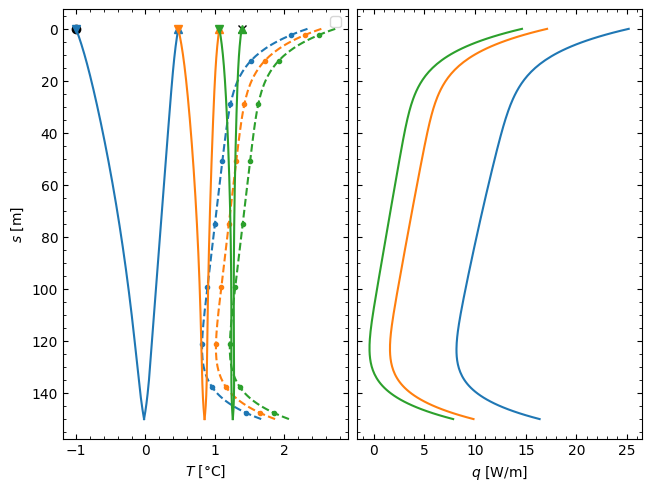

In [8]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
axs[0].plot(T_f_in2, s_eval[0, 0], 'ko')
axs[0].plot(T_f_out, s_eval[0, 0], 'kx')
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
for i in range(field.n_boreholes):
    axs[0].plot(T_b_eval[i], s_eval[:, i], '--', color=f'C{i}')
    axs[0].plot(T_b_nodes[i], s_nodes[:, i], '.', color=f'C{i}')
    axs[0].plot(T_f[i], s_eval[:, i], '-', color=f'C{i}')
    axs[0].plot(T_fb_in[i], s_eval[0, i], 'v', color=f'C{i}')
    axs[0].plot(T_fb_out[i], s_eval[0, i], '^', color=f'C{i}')
    axs[1].plot(q[i], s_eval[:, i], '-', color=f'C{i}')
axs[0].legend()
plt.show()

In [9]:
### Solution using pygfunction2

In [10]:
# Borehole object
field_pygfunction = gt.borefield.Borefield(L, D, r_b, p_head[:, 0], p_head[:, 1])
n_boreholes = field_pygfunction.nBoreholes
bore_connectivity = [i - 1 for i in range(n_boreholes)]

In [11]:
# Evaluation points
n_segments = 51
xi_edges = np.linspace(-1., 1., num=n_segments + 1)
xi_segments = 0.5 * (xi_edges[1:] + xi_edges[:-1])
s_segments = field.longitudinal_position(xi_segments)
T_b_segments = f_T_b(xi_segments, n_nodes, np.arange(field.n_boreholes)).flatten()

In [12]:
# Pipe thermal resistance
R_p = gt.pipes.conduction_thermal_resistance_circular_pipe(
        r_p_in, r_p_out, k_p)
# Fluid to inner pipe wall thermal resistance (Single U-tube)
h_f = gt.pipes.convective_heat_transfer_coefficient_circular_pipe(
        m_flow, r_p_in, fluid.viscosity(), fluid.density(), fluid.conductivity(), fluid.specific_heat(), epsilon)
R_f = 1.0 / (h_f * 2 * np.pi * r_p_in)

# Single U-tube, same for all boreholes in the bore field
UTubes = []
for borehole in field_pygfunction:
    SingleUTube = gt.pipes.SingleUTube(
        p, r_p_in, r_p_out, borehole, k_s, k_b, R_f + R_p)
    UTubes.append(SingleUTube)
network_pygfunction = gt.networks.Network(
    field_pygfunction,
    UTubes,
    bore_connectivity=bore_connectivity)

In [13]:
# Heat extraction rate along the boreholes
q_pygfunction = (network_pygfunction.get_borehole_heat_extraction_rate(T_f_in, T_b_segments, m_flow, cp_f, n_segments).reshape((n_boreholes, n_segments)).T / (field_pygfunction.H / n_segments)).T
q_avgb_pygfunction = network_pygfunction.get_fluid_heat_extraction_rate(T_f_in, T_b_segments, m_flow, cp_f, n_segments) / field_pygfunction.H
q_avg_pygfunction = network_pygfunction.get_network_heat_extraction_rate(T_f_in, T_b_segments, m_flow, cp_f, n_segments) / field_pygfunction.H.sum()
# Inlet fluid temperature
T_f_in2_pygfunction = network_pygfunction.get_network_inlet_temperature(q_avg * field_pygfunction.H.sum(), T_b_segments, m_flow, cp_f, n_segments)
T_fb_in_pygfunction = network_pygfunction.get_inlet_temperature(T_f_in, T_b_segments, m_flow, cp_f, n_segments)
# Outlet fluid temperature
T_fb_out_pygfunction = network_pygfunction.get_outlet_temperature(T_f_in, T_b_segments, m_flow, cp_f, n_segments)
T_f_out_pygfunction = network_pygfunction.get_network_outlet_temperature(T_f_in, T_b_segments, m_flow, cp_f, n_segments)
# Fluid temperature along the boreholes
T_f_pygfunction = np.zeros((n_boreholes, n_eval, 2))
for i, _pipe in enumerate(UTubes):
    T_f_pygfunction[i] = _pipe.get_temperature(s_eval[:, i], T_fb_in_pygfunction[i], T_b_segments.reshape((n_boreholes, n_segments))[i], m_flow, np.array([cp_f]))

C:\Users\massi\AppData\Local\Temp\ipykernel_45236\1276595307.py:16: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()


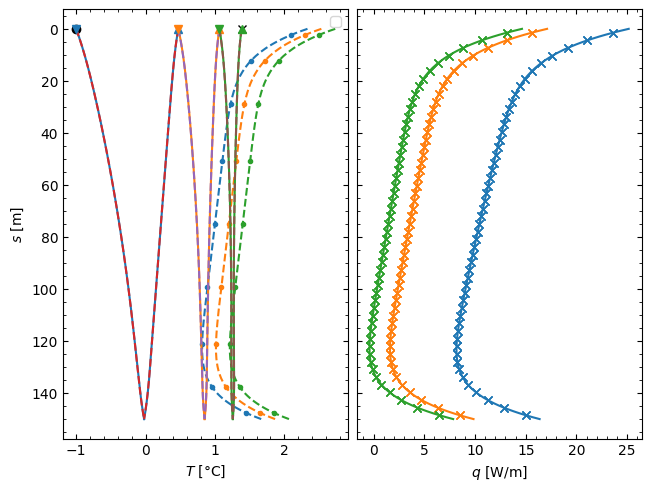

In [14]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$T$ [°C]', '$s$ [m]'], inverse_y=True)
axs[0].plot(T_f_in2_pygfunction, s_eval[0, 0], 'ko')
axs[0].plot(T_f_out_pygfunction, s_eval[0, 0], 'kx')
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel('$q$ [W/m]')
for i in range(field.n_boreholes):
    axs[0].plot(T_b_eval[i], s_eval[:, i], '--', color=f'C{i}')
    axs[0].plot(T_b_nodes[i], s_nodes[:, i], '.', color=f'C{i}')
    axs[0].plot(T_f[i], s_eval[:, i], '-', color=f'C{i}')
    axs[0].plot(T_f_pygfunction[i], s_eval[:, i], '--', color=f'C{i + n_boreholes}')
    axs[0].plot(T_fb_in_pygfunction[i], s_eval[0, i], 'v', color=f'C{i}')
    axs[0].plot(T_fb_out_pygfunction[i], s_eval[0, i], '^', color=f'C{i}')
    axs[1].plot(q[i], s_eval[:, i], '-', color=f'C{i}')
    axs[1].plot(q_pygfunction[i], s_segments, 'x', color=f'C{i}')
axs[0].legend()
plt.show()

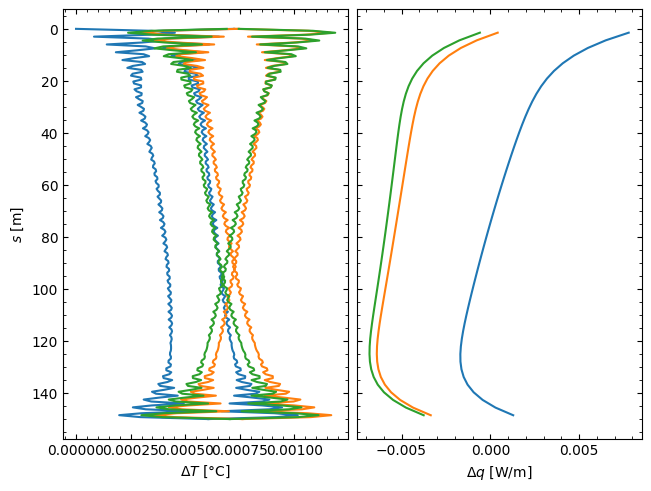

In [15]:
fig, axs = plt.subplots(ncols=2, sharey=True, constrained_layout=True)
axs[0] = gt3.plot._format_axis(axs[0], [r'$\Delta T$ [°C]', '$s$ [m]'], inverse_y=True)
axs[1] = gt3.plot._format_axis(axs[1], inverse_y=True)
axs[1].set_xlabel(r'$\Delta q$ [W/m]')
q_segments = network.heat_extraction_rate(basis, xi_segments, m_flow, T_f_in, T_b_nodes)
for i in range(field.n_boreholes):
    axs[0].plot(T_f[i] - T_f_pygfunction[i], s_eval[:, i], '-', color=f'C{i}')
    axs[1].plot(q_segments[i] - q_pygfunction[i], s_segments[:, i], '-', color=f'C{i}')
plt.show()

In [16]:
print(f'Outlet fluid temperature (pygfunction3): {T_f_out:.4f} °C')
print(f'Outlet fluid temperature (pygfunction2): {T_f_out_pygfunction:.4f} °C')
print(f'Average heat extraction rate (pygfunction3): {q_avg:.4f} W/m')
print(f'Average heat extraction rate (pygfunction2): {q_avg_pygfunction:.4f} W/m')
print(f'Effective borefield thermal resistance (pygfunction3): {network.effective_borefield_thermal_resistance(m_flow):.6f} K.m/W')
print(f'Effective borefield thermal resistance (pygfunction2): {gt.networks.network_thermal_resistance(network_pygfunction, m_flow, cp_f):.6f} K.m/W')

Outlet fluid temperature (pygfunction3): 1.3847 °C
Outlet fluid temperature (pygfunction2): 1.3841 °C
Average heat extraction rate (pygfunction3): 6.3224 W/m
Average heat extraction rate (pygfunction2): 6.3205 W/m
Effective borefield thermal resistance (pygfunction3): 0.199912 K.m/W
Effective borefield thermal resistance (pygfunction2): 0.199930 K.m/W
